In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [3]:
# Loading the Amazon dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [5]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [6]:
# Part 1: Analyzing Best-Seller Trends Across Product Categories

# Create a crosstab between the product category and the isBestSeller status
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [7]:
df['category'].nunique()

296

In [31]:
# Are there categories where being a best-seller is more prevalent? 296 rows, so small enough to have a visual glance at the whole list
#print(crosstab_result.to_string())

In [9]:
# Calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.
# Only show the top 20

bestseller_proportion = (
    df.groupby('category')['isBestSeller']
      .mean()
      .sort_values(ascending=False)
      .head(20)
)
bestseller_proportion

category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Professional Medical Supplies     0.027344
PC & Video Games                  0.025466
Bakeware                          0.025105
Material Handling Products        0.025000
Bedding Accessories               0.024390
Tableware                         0.024096
Arts & Crafts                     0.024086
Baby                              0.022658
Lighting                          0.022556
Window Treatments                 0.020921
Name: isBestSeller, dtype: float64

In [10]:
# Summary of that stats for each category

category_stats = (
    df.groupby('category')
      .agg(total_products=('isBestSeller', 'size'),
          bestseller_count=('isBestSeller', 'sum'),
          bestseller_proportion=('isBestSeller', 'mean'))
      .sort_values('bestseller_proportion', ascending=False)
)
category_stats

,total_products,bestseller_count,bestseller_proportion
category,,,
Grocery,9564,556,0.058135
Smart Home Security & Lighting,104,6,0.057692
Health & Personal Care,9569,552,0.057686
Mobile Phone Accessories,259,11,0.042471
Power & Hand Tools,8659,306,0.035339
...,...,...,...
"CD, Disc & Tape Players",8798,0,0.000000
General Music-Making Accessories,259,0,0.000000
Snowboard Boots,1449,0,0.000000


In [33]:
# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category

from scipy.stats import chi2_contingency

# Chi-square test for 'category' and 'isBestSeller'
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [12]:
# Check if it's really zero or just very small
print(f"{chi2_p_value:.100e}")

# Since the p-value looks to be zero, something appears to be wrong with the data.

0.0000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000e+00


In [13]:
# Compute Cramér's V to understand the strength of association between best-seller status and category

from scipy.stats.contingency import association

# Computing the association between variables in 'crosstab_result' using the "cramer" method
association(crosstab_result, method="cramer")

0.1222829439760564

In [15]:
# ** Findings: There is a statistically significant relationship between category and bestseller status because the p-value is less than 0.05, 
# but the association is very weak because Cramer's is 0.1 **

<Axes: xlabel='category'>

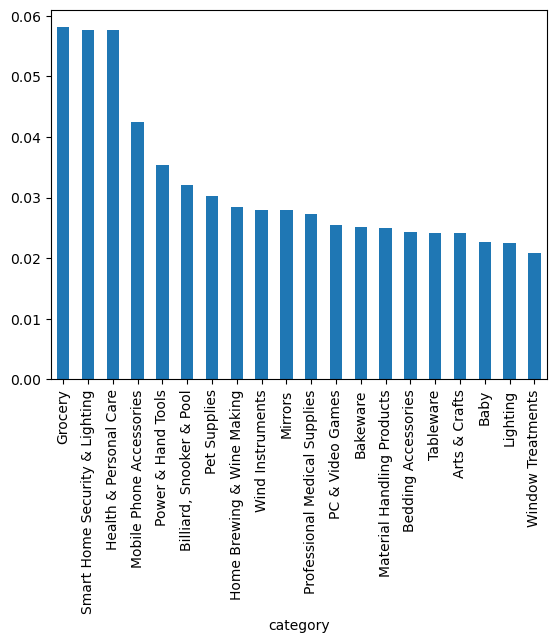

In [16]:
# Visualize the relationship between product categories and the best-seller status using a stacked bar chart

# Plotting a stacked bar chart for the 'bestseller_proportion' data
bestseller_proportion.plot(kind="bar", stacked=True)

In [27]:
# Part 2: Exploring Product Prices and Ratings Across Categories and Brands

# Preliminary Step: Remove outliers in product prices

def tukeys_test_outliers(data):
    Q1 = df['price'].quantile(0.25)
    Q3 = df['price'].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Identify the outliers and exclude them from the dataset
    excl_outliers = df[
    (df['price'] >= lower_bound) &
    (df['price'] <= upper_bound)]
    
    return excl_outliers

In [55]:
df_no_outliers = tukeys_test_outliers(df)
df_no_outliers

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


/var/folders/f3/4nxnf97x2z999nrldxm7ct1c0000gn/T/ipykernel_58114/731466183.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x='category', y='price', palette='coolwarm')


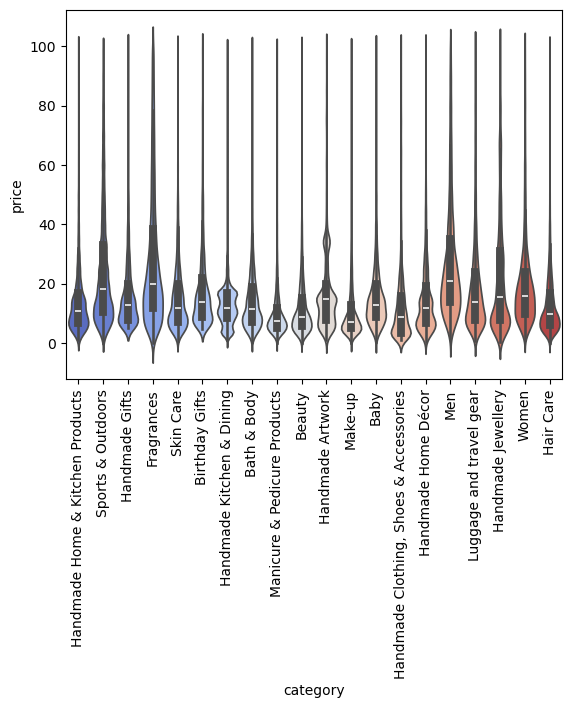

In [56]:
# Use a violin plot to visualize the distribution of price across different product categories. 
# Filter out the top 20 categories based on count for better visualization.

top20_categories = df_no_outliers['category'].value_counts().head(20).index

df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]

sns.violinplot(data=df_top20, x='category', y='price', palette='coolwarm')
plt.xticks(rotation=90)
plt.show()



In [41]:
# Which product category tends to have the highest median price? Don't filter here by top categories.

category_medians = df_clean.groupby('category')['price'].median().sort_values(ascending=False)
category_medians

category
Desktop PCs              74.00
Boxing Shoes             69.79
Tablets                  69.00
Graphics Cards           68.54
Motherboards             67.92
                         ...  
Adapters                  7.05
Make-up                   7.00
Signs & Plaques           6.99
Arts & Crafts             5.99
Office Paper Products     4.37
Name: price, Length: 296, dtype: float64

In [42]:
category_medians.head(20)

category
Desktop PCs                74.000
Boxing Shoes               69.790
Tablets                    69.000
Graphics Cards             68.540
Motherboards               67.920
Made in Italy Handmade     64.000
Digital Frames             63.900
Streaming Clients          62.680
Golf Shoes                 62.390
Ski Helmets                61.330
Hockey Shoes               57.800
Cycling Shoes              55.990
Home Office Furniture      55.620
Skiing Poles               55.230
Computer Cases             54.990
Motorbike Batteries        54.200
Dining Room Furniture      53.000
Motorbike Drive & Gears    52.600
3D Printers                52.195
Downhill Ski Boots         51.090
Name: price, dtype: float64

In [44]:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

# Top 10 categories by number of products
top10_categories = (df_clean['category'].value_counts().head(10).index)

top10_categories

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')

In [47]:
# Average price for those categories
avg_price_top10 = (df_clean[df_clean['category'].isin(top10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)
avg_price_top10

category
Sports & Outdoors                         25.172065
Birthday Gifts                            18.600195
Handmade Gifts                            17.395112
Skin Care                                 15.654722
Bath & Body                               14.678683
Hair Care                                 13.461408
Handmade Clothing, Shoes & Accessories    12.958639
Beauty                                    12.523480
Make-up                                   10.612918
Manicure & Pedicure Products              10.231825
Name: price, dtype: float64

<Axes: xlabel='category', ylabel='avg_price'>

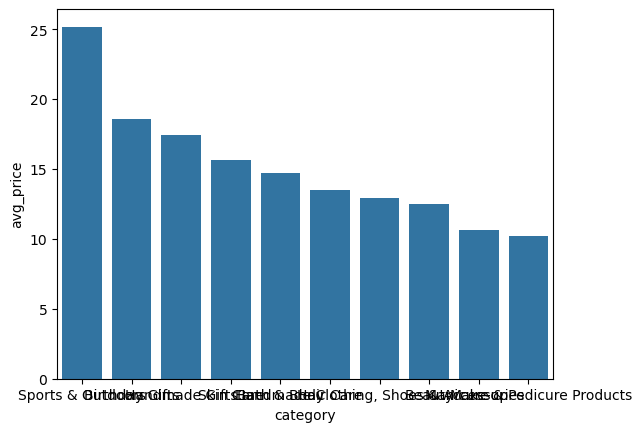

In [58]:
# Plotting the bar chart

avg_price_df = avg_price_top10.reset_index()
avg_price_df.columns = ['category', 'avg_price']

sns.barplot(data=avg_price_df, x='category', y='avg_price')

In [60]:
# Which product category commands the highest average price? Don't filter here by top categories.

category_avg_prices = (
    df_clean.groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
)

print(category_avg_prices.head(10))

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64


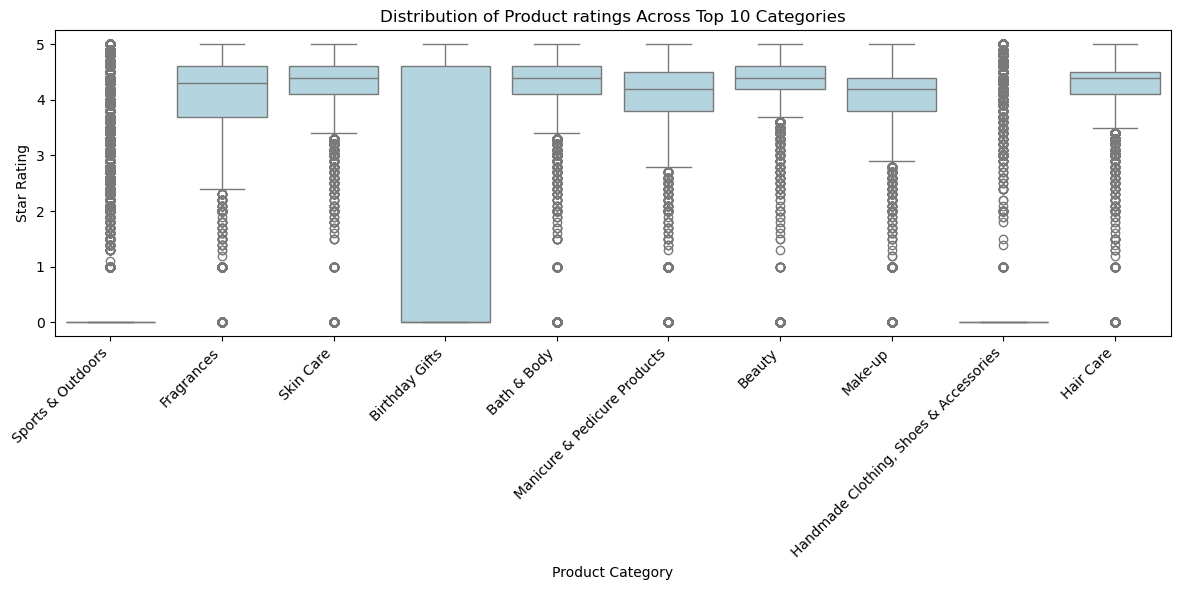

In [77]:
# Visualize the distribution of product ratings based on their category using side-by-side box plots. 
# Filter out the top 10 categories based on count for better visualization.

# 1. Get the names of the top 10 categories by count
top_10_categories = df['category'].value_counts().head(10).index

# 2. Filter the DataFrame for only those top 10 categories
df_top10 = df[df['category'].isin(top_10_categories)]

# 3. Create the side-by-side box plot
plt.figure(figsize=(12, 6))

sns.boxplot(data=df_top10, x='category', y='stars', color="lightblue")

# 4. Clean up the labels and formatting
plt.xticks(rotation=45, ha='right')
plt.title('Distribution of Product ratings Across Top 10 Categories')
plt.xlabel('Product Category')
plt.ylabel('Star Rating')

plt.tight_layout()
plt.show()

# Which category tends to receive the highest median rating from customers? Don't filter here by top categories.
# Skin Care and Beauty seem to receive the highest median ratings

In [78]:
# Calculate the correlation coefficient between price and stars

# Calculating the Pearson correlation coefficient between 'price' and 'stars' columns
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.12490673262148537)

In [79]:
# Calculating the Spearman rank correlation between 'SalePrice' and 'GrLivArea' 
correlation = df['price'].corr(df['stars'], method='spearman')
correlation

np.float64(-0.13316425462433998)

In [81]:
# There is a weak negative relationship between price and rating. 
# These findings may be distorted because of the zero star ratings and zero price values.

<Axes: xlabel='stars', ylabel='price'>

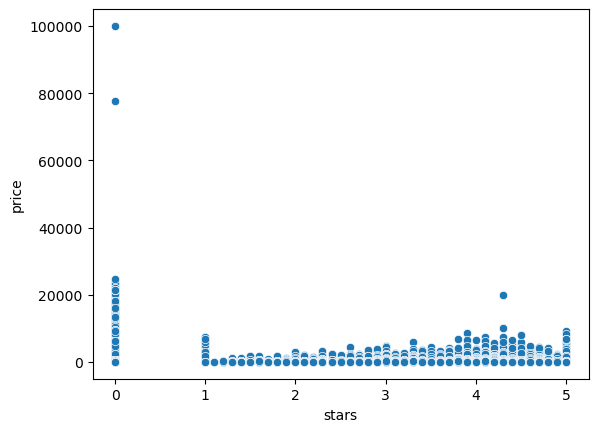

In [84]:
# Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

sns.scatterplot(data=df, x='stars', y='price')

# Most products with positive ratings fall under 20 000 price range. There are more products with ratings between 4 and 5.

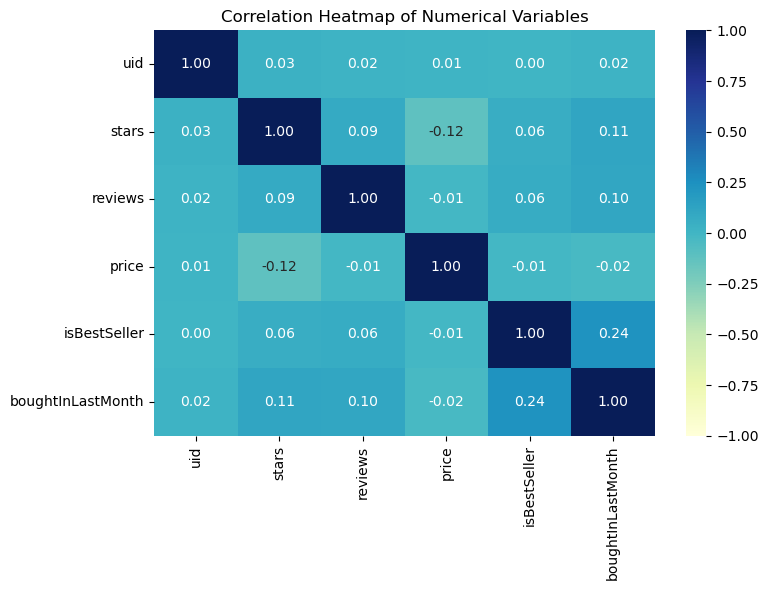

In [86]:
#Use a correlation heatmap to visualize correlations between all numerical variables.

#sns.heatmap(crosstab_result, annot=True, cmap="YlGnBu", fmt="d")

# Calculate correlation matrix for ALL numerical variables

corr_matrix = df.corr(numeric_only=True)

# 2. Plot the heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(corr_matrix, annot=True, cmap="YlGnBu", fmt=".2f", vmin=-1, vmax=1)

plt.title('Correlation Heatmap of Numerical Variables')
plt.tight_layout()
plt.show()

In [ ]:
# Examine if product prices typically follow a normal distribution using a QQ plot.

